In [11]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('spam.csv', encoding='latin-1')
df = df[['v1', 'v2']]
df.columns = ['label', 'text']
print(df.shape)
df.head()

(5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


label
ham     4825
spam     747
Name: count, dtype: int64

label
ham     86.6
spam    13.4
Name: proportion, dtype: float64

Duplicates: 403


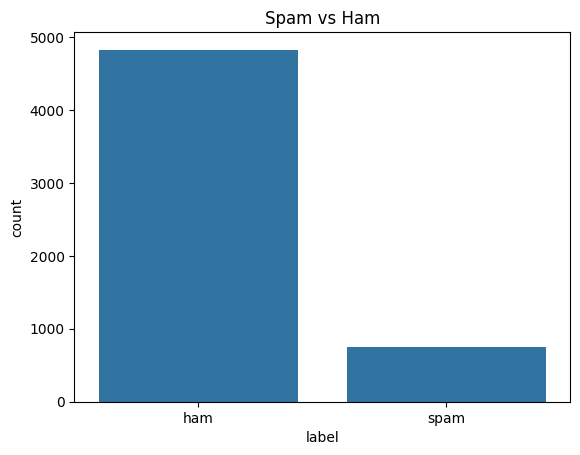

In [12]:
print(df['label'].value_counts())
print()
print((df['label'].value_counts(normalize=True) * 100).round(1))
print()
print("Duplicates:", df.duplicated().sum())

sns.countplot(data=df, x='label')
plt.title('Spam vs Ham')
plt.show()

In [13]:
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
dups_removed = rows_before - len(df)
print("Removed", dups_removed, "duplicate messages")
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

Removed 403 duplicate messages


In [14]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def clean(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = [w for w in text.split() if w not in ENGLISH_STOP_WORDS]
    return ' '.join(words)

df['clean_text'] = df['text'].apply(clean)
df[['text', 'clean_text']].head()

,text,clean_text
0,"Go until jurong point, crazy.. Available only ...",jurong point crazy available bugis n great wor...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c say
4,"Nah I don't think he goes to usf, he lives aro...",nah don t think goes usf lives


### TF-IDF
TF-IDF (term frequency, inverse document frequency) turns each message into numbers. A word scores higher when it appears often in a message but rarely across all messages, so common words like "the" count for little and distinctive words like "winner" or "claim" count for more. This lets the models focus on the words that actually separate spam from normal messages.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['clean_text'], df['label_num'], test_size=0.2, random_state=42, stratify=df['label_num']
)

tfidf = TfidfVectorizer()
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)
print("Training messages:", X_train.shape[0], "| Test messages:", X_test.shape[0])
print("Vocabulary size:", X_train.shape[1])

Training messages: 4135 | Test messages: 1034
Vocabulary size: 6477


In [16]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained")

Multinomial Naive Bayes trained
Logistic Regression trained


In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rows = []
for name, model in models.items():
    p = model.predict(X_test)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p),
                 "F1": f1_score(y_test, p)})
results_df = pd.DataFrame(rows).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1
0,Multinomial Naive Bayes,0.967,0.990,0.748,0.852
1,Logistic Regression,0.957,0.989,0.672,0.800


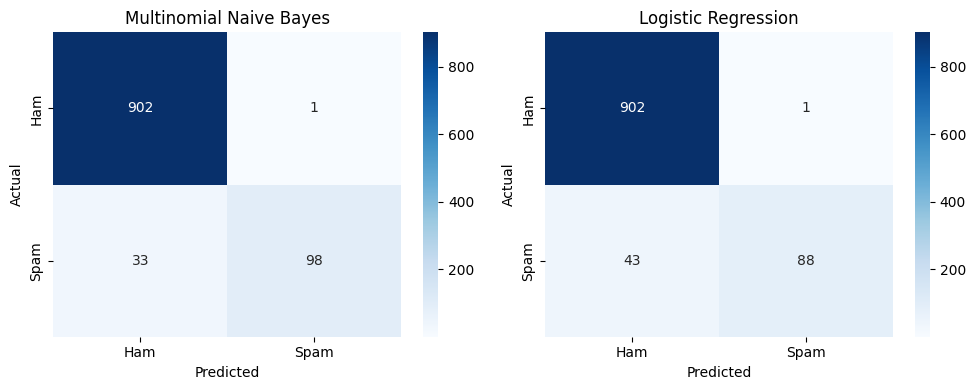

===== Multinomial Naive Bayes =====
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       0.99      0.75      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.97      1034

===== Logistic Regression =====
              precision    recall  f1-score   support

         Ham       0.95      1.00      0.98       903
        Spam       0.99      0.67      0.80       131

    accuracy                           0.96      1034
   macro avg       0.97      0.84      0.89      1034
weighted avg       0.96      0.96      0.95      1034



In [18]:
from sklearn.metrics import confusion_matrix, classification_report

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

for name, model in models.items():
    print("=====", name, "=====")
    print(classification_report(y_test, model.predict(X_test), target_names=['Ham', 'Spam']))

### Why recall matters for spam detection
Recall is the share of real spam messages the model catches. A low recall means spam slips through to the inbox, which is the main thing a spam filter exists to stop. Precision matters as well, because wrongly marking a genuine message as spam can hide something important, so a good filter needs both. The model with the better balance of the two (a high F1-score) is the stronger choice.

In [19]:
best = results_df.sort_values('F1', ascending=False).iloc[0]
ham_pct = (df['label'] == 'ham').mean() * 100
spam_pct = (df['label'] == 'spam').mean() * 100

table = "\n".join(
    f"| {r.Model} | {r.Accuracy:.3f} | {r.Precision:.3f} | {r.Recall:.3f} | {r.F1:.3f} |"
    for r in results_df.itertuples()
)

insights = f"""- The dataset is imbalanced: {ham_pct:.1f}% ham and {spam_pct:.1f}% spam, so accuracy alone can look good even for a weak model. Precision, recall and F1 give a fairer picture.
- Removed {dups_removed} duplicate messages before training.
- Best model by F1-score: {best.Model} (accuracy {best.Accuracy:.3f}, precision {best.Precision:.3f}, recall {best.Recall:.3f}, F1 {best.F1:.3f})."""

readme = f"""# Email Spam Detection with Machine Learning

**Oasis Infobyte Data Science Internship | Task 4**

## Objective
Build a natural language processing classifier that separates spam messages from legitimate (ham) ones.

## Dataset
SMS Spam Collection from Kaggle: {len(df)} messages after removing duplicates ({ham_pct:.1f}% ham, {spam_pct:.1f}% spam).

## Steps
1. Loaded the data and checked the class distribution
2. Removed {dups_removed} duplicate messages
3. Preprocessed the text: lowercase, removed punctuation and numbers, removed stopwords
4. Converted the text to numbers with a TF-IDF vectoriser
5. Split the data 80/20 (stratified so both sets keep the same spam share)
6. Trained Multinomial Naive Bayes and Logistic Regression
7. Evaluated both with accuracy, precision, recall, F1-score and confusion matrices

## Results
| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
{table}

## Key Insights
{insights}

## Limitations
The text cleaning removes numbers and punctuation, which can carry spam signals (for example prices and phone numbers). Keeping them could improve recall.

## How to Run
1. Install the libraries: `pip3 install pandas numpy matplotlib seaborn scikit-learn jupyter`
2. Open `spam_detection.ipynb` in VS Code or Jupyter
3. Click Run All

## Screenshots
See the `screenshots` folder.
"""

print("===== OBSERVATIONS (paste into a Markdown cell at the end of the notebook) =====")
print(insights)
print()
print("===== README (paste into README.md) =====")
print(readme)

===== OBSERVATIONS (paste into a Markdown cell at the end of the notebook) =====
- The dataset is imbalanced: 87.4% ham and 12.6% spam, so accuracy alone can look good even for a weak model. Precision, recall and F1 give a fairer picture.
- Removed 403 duplicate messages before training.
- Best model by F1-score: Multinomial Naive Bayes (accuracy 0.967, precision 0.990, recall 0.748, F1 0.852).

===== README (paste into README.md) =====
# Email Spam Detection with Machine Learning

**Oasis Infobyte Data Science Internship | Task 4**

## Objective
Build a natural language processing classifier that separates spam messages from legitimate (ham) ones.

## Dataset
SMS Spam Collection from Kaggle: 5169 messages after removing duplicates (87.4% ham, 12.6% spam).

## Steps
1. Loaded the data and checked the class distribution
2. Removed 403 duplicate messages
3. Preprocessed the text: lowercase, removed punctuation and numbers, removed stopwords
4. Converted the text to numbers with a TF-IDF 

### Observations

In [20]:
best = results_df.sort_values('F1', ascending=False).iloc[0]
ham_pct = (df['label'] == 'ham').mean() * 100
spam_pct = (df['label'] == 'spam').mean() * 100

table = "\n".join(
    f"| {r.Model} | {r.Accuracy:.3f} | {r.Precision:.3f} | {r.Recall:.3f} | {r.F1:.3f} |"
    for r in results_df.itertuples()
)

insights = f"""- The dataset is imbalanced: {ham_pct:.1f}% ham and {spam_pct:.1f}% spam, so accuracy alone can look good even for a weak model. Precision, recall and F1 give a fairer picture.
- Removed {dups_removed} duplicate messages before training.
- Best model by F1-score: {best.Model} (accuracy {best.Accuracy:.3f}, precision {best.Precision:.3f}, recall {best.Recall:.3f}, F1 {best.F1:.3f})."""

readme = f"""# Email Spam Detection with Machine Learning

**Oasis Infobyte Data Science Internship | Task 4**

## Objective
Build a natural language processing classifier that separates spam messages from legitimate (ham) ones.

## Dataset
SMS Spam Collection from Kaggle: {len(df)} messages after removing duplicates ({ham_pct:.1f}% ham, {spam_pct:.1f}% spam).

## Steps
1. Loaded the data and checked the class distribution
2. Removed {dups_removed} duplicate messages
3. Preprocessed the text: lowercase, removed punctuation and numbers, removed stopwords
4. Converted the text to numbers with a TF-IDF vectoriser
5. Split the data 80/20 (stratified so both sets keep the same spam share)
6. Trained Multinomial Naive Bayes and Logistic Regression
7. Evaluated both with accuracy, precision, recall, F1-score and confusion matrices

## Results
| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
{table}

## Key Insights
{insights}

## Limitations
The text cleaning removes numbers and punctuation, which can carry spam signals (for example prices and phone numbers). Keeping them could improve recall.

## How to Run
1. Install the libraries: `pip3 install pandas numpy matplotlib seaborn scikit-learn jupyter`
2. Open `spam_detection.ipynb` in VS Code or Jupyter
3. Click Run All

## Screenshots
See the `screenshots` folder.
"""

print("===== OBSERVATIONS (paste into a Markdown cell at the end of the notebook) =====")
print(insights)
print()
print("===== README (paste into README.md) =====")
print(readme)

===== OBSERVATIONS (paste into a Markdown cell at the end of the notebook) =====
- The dataset is imbalanced: 87.4% ham and 12.6% spam, so accuracy alone can look good even for a weak model. Precision, recall and F1 give a fairer picture.
- Removed 403 duplicate messages before training.
- Best model by F1-score: Multinomial Naive Bayes (accuracy 0.967, precision 0.990, recall 0.748, F1 0.852).

===== README (paste into README.md) =====
# Email Spam Detection with Machine Learning

**Oasis Infobyte Data Science Internship | Task 4**

## Objective
Build a natural language processing classifier that separates spam messages from legitimate (ham) ones.

## Dataset
SMS Spam Collection from Kaggle: 5169 messages after removing duplicates (87.4% ham, 12.6% spam).

## Steps
1. Loaded the data and checked the class distribution
2. Removed 403 duplicate messages
3. Preprocessed the text: lowercase, removed punctuation and numbers, removed stopwords
4. Converted the text to numbers with a TF-IDF 